In [25]:
import pandas as pd

In [26]:
clust_res = pd.read_csv('data/clust-results.tsv', sep='\t', header=None)
clust_res.columns = ['type', 'cluster_id', 'query_length', 'similarity', 'strand', 0, 1, 'align_res', 'query_label', 'centroid_label']
clust_res = clust_res[['type', 'cluster_id', 'query_length', 'similarity', 'strand', 'align_res', 'query_label']]

In [27]:
cluster = clust_res[(clust_res['type'] == 'S') | (clust_res['type'] == 'H')]
cluster.head(20)

,type,cluster_id,query_length,similarity,strand,align_res,query_label
0,S,0,801,*,*,*,L04457.1
1,S,1,780,*,*,*,BK011976.1
2,H,1,780,100.0,+,=,NC_063789.1
3,S,2,777,*,*,*,AY894835.1
4,S,3,777,*,*,*,AY898627.1
5,H,3,777,100.0,+,=,AY898628.1
6,S,4,777,*,*,*,BK011977.1
7,S,5,777,*,*,*,BK011979.1
8,S,6,777,*,*,*,BK011980.1
9,S,7,777,*,*,*,BK011981.1


In [28]:
cluster.value_counts(subset='cluster_id').sort_values(ascending=False)

cluster_id
2      150
15     134
3      112
8      109
94      79
      ... 
73       1
691      1
692      1
693      1
696      1
Name: count, Length: 1627, dtype: int64

In [29]:
db = pd.read_csv('data/cox2-db-filtered.csv', sep='\t')
db

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,cox2_end,cox2_strand
0,MK173058.1,18-FEB-2019,Peronospora variabilis isolate Kari cytochrome...,"Rollano-Penaloza,O.M.",GTATTATTAACTTTCATCATGATTTGATGTTTTTTTTAATTATTGT...,544,Peronospora variabilis,162102,<0,>544,1.0
1,MH234579.1,02-FEB-2019,Albugo candida isolate G725 cytochrome oxidase...,"Latinovic,J., Latinovic,N., Jakse,J. and Radis...",GCAAAATGGGTTTTCAAGATCCAGCTACTCCTGTTATGGAAGGTAT...,632,Albugo candida,65357,<0,>632,1.0
2,MH665652.1,27-JAN-2019,Bremia itoana cytochrome c oxidase subunit II ...,"Choi,Y.J., Park,J.H., Lee,J. and Shin,H.D.",GCAACACCTGTAATGGAAGGTATCATTAATTTTCATCATGATATTA...,584,Bremia itoana,2507514,<0,>584,1.0
3,KY412456.1,10-JAN-2019,Pustula xinyuanensis voucher HMUT 3476 cytochr...,"Xu,B., Choi,Y.J., Song,J.G., Xi,P.G., Li,M.H.,...",GTAATGGAAGGAATTATAAACTTTCATCATGATTTAATGTTTTTTT...,578,Pustula xinyuanensis,2069635,<0,>578,1.0
4,KY412455.1,10-JAN-2019,Pustula xinyuanensis voucher HMUT 3473 cytochr...,"Xu,B., Choi,Y.J., Song,J.G., Xi,P.G., Li,M.H.,...",GTAATGGAAGGAATTATAAACTTTCATCATGATTTAATGTTTTTTT...,561,Pustula xinyuanensis,2069635,<0,>561,1.0
...,...,...,...,...,...,...,...,...,...,...,...
5055,OK574284.1,28-SEP-2022,Phytophthora cactorum voucher 262HNP mitochond...,"Li,M. and Lin,T.",ATGATAATAACAAATTATATAAATAACCAATTCACTTTTTTAGATA...,38014,Phytophthora cactorum,29920,37042,37819,1.0
5056,OK555490.1,28-SEP-2022,Phytophthora cactorum voucher CH98PA11 mitocho...,"Li,M. and Lin,T.",ATGATAATAACAAATTATATAAATAACCAATTCACTTTTTTAGATA...,38016,Phytophthora cactorum,29920,37044,37821,1.0
5057,ON286950.1,14-SEP-2022,Globisporangium spinosum cytochrome c oxidase ...,"Hossain,M.D., Akter,A. and Wick,R.L.",CGATTTAATGTTTTTTTTAATTGTTGTAACTATTTTTGTTTGTTGG...,512,Globisporangium spinosum,2125998,<0,>512,1.0
5058,ON532704.1,13-SEP-2022,Albugo candida strain LemidPRAru20 cytochrome ...,"Zielinski,E.C., Claus,A., Hahn,M.H., Koch,G. a...",AAGATCCAGCTACTCCTGTTATGGAAGGTATTATTAATTTTCATCA...,519,Albugo candida,65357,<0,>519,1.0


In [30]:
merged = db.merge(cluster, how='left', left_on='accession', right_on='query_label')
merged['trimed_seq_len'] = merged['sequence'].str.len()
merged

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,cox2_end,cox2_strand,type,cluster_id,query_length,similarity,strand,align_res,query_label,trimed_seq_len
0,MK173058.1,18-FEB-2019,Peronospora variabilis isolate Kari cytochrome...,"Rollano-Penaloza,O.M.",GTATTATTAACTTTCATCATGATTTGATGTTTTTTTTAATTATTGT...,544,Peronospora variabilis,162102,<0,>544,1.0,H,640,544,100.0,+,=,MK173058.1,544
1,MH234579.1,02-FEB-2019,Albugo candida isolate G725 cytochrome oxidase...,"Latinovic,J., Latinovic,N., Jakse,J. and Radis...",GCAAAATGGGTTTTCAAGATCCAGCTACTCCTGTTATGGAAGGTAT...,632,Albugo candida,65357,<0,>632,1.0,S,543,632,*,*,*,MH234579.1,632
2,MH665652.1,27-JAN-2019,Bremia itoana cytochrome c oxidase subunit II ...,"Choi,Y.J., Park,J.H., Lee,J. and Shin,H.D.",GCAACACCTGTAATGGAAGGTATCATTAATTTTCATCATGATATTA...,584,Bremia itoana,2507514,<0,>584,1.0,S,758,584,*,*,*,MH665652.1,584
3,KY412456.1,10-JAN-2019,Pustula xinyuanensis voucher HMUT 3476 cytochr...,"Xu,B., Choi,Y.J., Song,J.G., Xi,P.G., Li,M.H.,...",GTAATGGAAGGAATTATAAACTTTCATCATGATTTAATGTTTTTTT...,578,Pustula xinyuanensis,2069635,<0,>578,1.0,S,863,578,*,*,*,KY412456.1,578
4,KY412455.1,10-JAN-2019,Pustula xinyuanensis voucher HMUT 3473 cytochr...,"Xu,B., Choi,Y.J., Song,J.G., Xi,P.G., Li,M.H.,...",GTAATGGAAGGAATTATAAACTTTCATCATGATTTAATGTTTTTTT...,561,Pustula xinyuanensis,2069635,<0,>561,1.0,H,863,561,100.0,+,=,KY412455.1,561
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5055,OK574284.1,28-SEP-2022,Phytophthora cactorum voucher 262HNP mitochond...,"Li,M. and Lin,T.",ATGATAATAACAAATTATATAAATAACCAATTCACTTTTTTAGATA...,38014,Phytophthora cactorum,29920,37042,37819,1.0,H,5,777,100.0,+,=,OK574284.1,777
5056,OK555490.1,28-SEP-2022,Phytophthora cactorum voucher CH98PA11 mitocho...,"Li,M. and Lin,T.",ATGATAATAACAAATTATATAAATAACCAATTCACTTTTTTAGATA...,38016,Phytophthora cactorum,29920,37044,37821,1.0,H,5,777,100.0,+,=,OK555490.1,777
5057,ON286950.1,14-SEP-2022,Globisporangium spinosum cytochrome c oxidase ...,"Hossain,M.D., Akter,A. and Wick,R.L.",CGATTTAATGTTTTTTTTAATTGTTGTAACTATTTTTGTTTGTTGG...,512,Globisporangium spinosum,2125998,<0,>512,1.0,S,1476,512,*,*,*,ON286950.1,512
5058,ON532704.1,13-SEP-2022,Albugo candida strain LemidPRAru20 cytochrome ...,"Zielinski,E.C., Claus,A., Hahn,M.H., Koch,G. a...",AAGATCCAGCTACTCCTGTTATGGAAGGTATTATTAATTTTCATCA...,519,Albugo candida,65357,<0,>519,1.0,S,1432,519,*,*,*,ON532704.1,519


In [31]:
#merged_groups = merged.groupby(by='cluster_id').apply(lambda group: group.sort_values('trimed_seq_len', ascending=False))
#filtered_df = merged[merged.groupby('cluster_id')['tax_id'].transform('nunique') > 1]
#filtered_df.to_csv('heterogenous-cluster.csv')
#merged_groups

In [32]:
df_sorted = merged.sort_values(by=['cluster_id', 'tax_id', 'trimed_seq_len'], ascending=[True, True, False])
df_sorted

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,cox2_end,cox2_strand,type,cluster_id,query_length,similarity,strand,align_res,query_label,trimed_seq_len
3372,L04457.1,25-JUL-2016,Phytophthora megasperma cytochrome c oxidase s...,"Shumard-Hudspeth,D.S. and Hudspeth,M.E.",ATGACAATCACAAATTATATCAACAATCAATTCACTTTTTTAGATA...,3572,Phytophthora megasperma,4788,793,1594,1.0,S,0,801,*,*,*,L04457.1,801
2179,GU222070.1,25-JUL-2016,Phytophthora megasperma isolate P3136 cytochro...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATTAACTTTCATCACGATTTAATGTTCTTTTTAA...,1003,Phytophthora megasperma,4788,<0,684,1.0,H,0,684,100.0,+,=,GU222070.1,684
2181,GU222068.1,25-JUL-2016,Phytophthora megasperma isolate P10340 cytochr...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATTAACTTTCATCACGATTTAATGTTCTTTTTAA...,946,Phytophthora megasperma,4788,<0,684,1.0,H,0,684,100.0,+,=,GU222068.1,684
604,BK011976.1,09-MAY-2022,TPA_asm: Hyaloperonospora arabidopsidis isolat...,"Winkworth,R.C., Neal,G., Ogas,R.A., Nelson,B.C...",ATGGTAATCAAAAATTATATAATAGATAAGCAATCTACTTTTTTAG...,38797,Hyaloperonospora arabidopsidis,272952,24700,25480,1.0,S,1,780,*,*,*,BK011976.1,780
4835,NC_063789.1,13-APR-2023,Hyaloperonospora arabidopsidis isolate Noks1 m...,"Winkworth,R.C., Neal,G., Ogas,R.A., Nelson,B.C...",ATGGTAATCAAAAATTATATAATAGATAAGCAATCTACTTTTTTAG...,38797,Hyaloperonospora arabidopsidis,272952,24700,25480,1.0,H,1,780,100.0,+,=,NC_063789.1,780
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
896,MK067061.1,01-DEC-2020,Plasmopara elegantissima voucher KUS-F23341 cy...,"Choi,Y.J., Gorg,M., Shin,H.D. and Thines,M.",GTATTGGAGTTATGAATATTCAGATAATTTAGAATTTTCAGACGAA...,203,Plasmopara elegantissima,2575762,<0,>203,1.0,H,1626,203,100.0,+,=,MK067061.1,203
897,MK067060.1,01-DEC-2020,Plasmopara elegantissima voucher KUS-F21824 cy...,"Choi,Y.J., Gorg,M., Shin,H.D. and Thines,M.",GTATTGGAGTTATGAATATTCAGATAATTTAGAATTTTCAGACGAA...,203,Plasmopara elegantissima,2575762,<0,>203,1.0,H,1626,203,100.0,+,=,MK067060.1,203
900,MK067057.1,01-DEC-2020,Plasmopara elegantissima voucher KUS-F20250 cy...,"Choi,Y.J., Gorg,M., Shin,H.D. and Thines,M.",GTATTGGAGTTATGAATATTCAGATAATTTAGAATTTTCAGACGAA...,203,Plasmopara elegantissima,2575762,<0,>203,1.0,H,1626,203,100.0,+,=,MK067057.1,203
901,MK067056.1,01-DEC-2020,Plasmopara elegantissima voucher KUS-F19566 cy...,"Choi,Y.J., Gorg,M., Shin,H.D. and Thines,M.",GTATTGGAGTTATGAATATTCAGATAATTTAGAATTTTCAGACGAA...,203,Plasmopara elegantissima,2575762,<0,>203,1.0,H,1626,203,100.0,+,=,MK067056.1,203


In [33]:
def filter_func(group: pd.DataFrame):
    # only keep identical sequences if they are from different species
    # Removes identical (but potentially shorter) sequences from the same species
    # ==> Remove redundant sequences that don't give any new information
    # PRE: each group is sorted (desc) by trimed_seq_len
    if group.shape[0] == 1:
        return group
    subgroup = group.groupby('tax_id', group_keys=False)
    return subgroup.apply(lambda sub: sub.iloc[0])

filtered_df = df_sorted.groupby('cluster_id', group_keys=False).apply(filter_func)
filtered_df

/tmp/ipykernel_3862446/708445845.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return subgroup.apply(lambda sub: sub.iloc[0])
/tmp/ipykernel_3862446/708445845.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return subgroup.apply(lambda sub: sub.iloc[0])
/tmp/ipykernel_3862446/708445845.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, a

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,cox2_end,cox2_strand,type,cluster_id,query_length,similarity,strand,align_res,query_label,trimed_seq_len
4788,L04457.1,25-JUL-2016,Phytophthora megasperma cytochrome c oxidase s...,"Shumard-Hudspeth,D.S. and Hudspeth,M.E.",ATGACAATCACAAATTATATCAACAATCAATTCACTTTTTTAGATA...,3572,Phytophthora megasperma,4788,793,1594,1.0,S,0,801,*,*,*,L04457.1,801
272952,BK011976.1,09-MAY-2022,TPA_asm: Hyaloperonospora arabidopsidis isolat...,"Winkworth,R.C., Neal,G., Ogas,R.A., Nelson,B.C...",ATGGTAATCAAAAATTATATAATAGATAAGCAATCTACTTTTTTAG...,38797,Hyaloperonospora arabidopsidis,272952,24700,25480,1.0,S,1,780,*,*,*,BK011976.1,780
4787,AY894835.1,26-JUL-2016,Phytophthora infestans haplotype Ia mitochondr...,"Avila-Adame,C., Gomez-Alpizar,L., Zismann,V., ...",ATGACAATAACAAATTATATAAATAATCAATTTACTTTTTTAGATA...,37922,Phytophthora infestans,4787,7624,8401,1.0,S,2,777,*,*,*,AY894835.1,777
283009,KJ408269.1,02-APR-2015,"Phytophthora andina mitochondrion, partial genome","Lassiter,E.S., Russ,C., Nusbaum,C., Zeng,Q., S...",ATGACAATAACAAATTATATAAATAATCAATTTACTTTTTTAGATA...,37883,Phytophthora andina,283009,7617,8394,1.0,H,2,777,100.0,+,=,KJ408269.1,777
4787,MH286887.1,19-MAR-2019,Phytophthora infestans voucher IT199999 mitoch...,"Cho,K.-S., Choi,J.-G., Cho,J.-H., Im,J.-S., Pa...",TTATACATTAAAATCAAAATTAATTTTATTTTTTAACCAAGTTAAA...,39872,Phytophthora infestans,4787,38640,39417,-1.0,H,3,777,100.0,-,=,MH286887.1,777
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
142,HM628758.1,07-DEC-2017,Plasmopara viticola strain U366 voucher HUH ex...,"Schroeder,S., Telle,S., Nick,P. and Thines,M.",TACTGGAGTTATGAATATTCCGATAATTTAGAGTTTTCAGATGAAC...,248,Plasmopara viticola,143451,<0,>248,1.0,S,1622,248,*,*,*,HM628758.1,248
517,KP979650.1,30-MAR-2015,Peronosclerospora sorghi isolate 3BSJBPS1 cyto...,"Rustiani,U.S., Sinaga,M.S., Wiyono,S. and Hida...",TCCAGCAACTCCAGTTATGGAAGGTATTATTAATTTTCATCATGAT...,241,Peronosclerospora sorghi,230839,<0,>241,1.0,S,1623,241,*,*,*,KP979650.1,241
867,EU595782.1,26-JUL-2016,Phytophthora sp. 4E4 cytochrome c oxidase subu...,"Hong,C., Gallegly,M.E., Richardson,P.A., Kong,...",CCATGGTATTGGAGTTACGAATATTCAGATAATTTAGAATTTTCAG...,210,Phytophthora irrigata,565287,<0,>210,1.0,S,1624,210,*,*,*,EU595782.1,210
2019374,MF372728.1,23-JUL-2017,Plasmopara destructor voucher GLM-F107554 cyto...,"Goerg,M., Ploch,S., Kruse,J., Kummer,V., Runge...",ACGGTATTGCCCAAGAATGTAAAACATCTGATGCAGTAATTAATAC...,203,Plasmopara destructor,2019374,<0,>203,-1.0,H,1625,203,100.0,+,=,MF372728.1,203


In [34]:
filtered_df.value_counts('tax_id').sort_values(ascending=False)

tax_id
65357     67
907947    52
143453    37
4792      28
143451    17
          ..
707994     1
707993     1
697890     1
697875     1
682055     1
Name: count, Length: 762, dtype: int64

In [35]:
filtered_df.to_csv('data/cox2-db-clust.csv', index=False, sep='\t')

In [36]:
filtered_df[filtered_df['tax_id'] == 4787].reset_index()

,index,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id,cox2_start,cox2_end,cox2_strand,type,cluster_id,query_length,similarity,strand,align_res,query_label,trimed_seq_len
0,4787,AY894835.1,26-JUL-2016,Phytophthora infestans haplotype Ia mitochondr...,"Avila-Adame,C., Gomez-Alpizar,L., Zismann,V., ...",ATGACAATAACAAATTATATAAATAATCAATTTACTTTTTTAGATA...,37922,Phytophthora infestans,4787,7624,8401,1.0,S,2,777,*,*,*,AY894835.1,777
1,4787,MH286887.1,19-MAR-2019,Phytophthora infestans voucher IT199999 mitoch...,"Cho,K.-S., Choi,J.-G., Cho,J.-H., Im,J.-S., Pa...",TTATACATTAAAATCAAAATTAATTTTATTTTTTAACCAAGTTAAA...,39872,Phytophthora infestans,4787,38640,39417,-1.0,H,3,777,100.0,-,=,MH286887.1,777
2,4787,JF771467.1,25-JUL-2016,Phytophthora infestans isolate P7722 cytochrom...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATTAACTTTCACCATGATTTAATGTTTTTTTTAA...,908,Phytophthora infestans,4787,<0,684,1.0,H,366,684,100.0,+,=,JF771467.1,684
3,2908,JF771491.1,25-JUL-2016,Phytophthora infestans isolate P15168 cytochro...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATTAACTTTCACCATGATTTAATGTTTTTTTTAA...,911,Phytophthora infestans,4787,<0,684,1.0,S,415,684,*,*,*,JF771491.1,684
4,4356,JQ439449.1,31-DEC-2012,Phytophthora infestans isolate P10646 cytochro...,"Martin,F. and Radmer,L.",ATGGAAGGTATTATTAACTTTCACCATGATTTAATGTTTTTTTTAA...,911,Phytophthora infestans,4787,<0,684,1.0,S,431,684,*,*,*,JQ439449.1,684
5,2843,PP356592.1,27-FEB-2024,Phytophthora infestans cytochrome oxidase subu...,"Azimova,N.S., Qobilov,F.B., Nazirov,M.M., Khal...",TTTCAAGATCCAGCAACTCCAGTTATGGAAGGTATTATTAACTTTC...,583,Phytophthora infestans,4787,<0,>583,1.0,S,762,583,*,*,*,PP356592.1,583
6,1166,KJ654169.1,12-MAR-2019,Phytophthora infestans isolate O17 cytochrome ...,"Choi,Y.J., Beakes,G., Glockling,S., Kruse,J., ...",AGCAACTCCAGTTATGGAAGGTATTATTAACTTTCACCATGATTTA...,581,Phytophthora infestans,4787,<0,>581,1.0,S,831,581,*,*,*,KJ654169.1,581


array([[<Axes: title={'center': 'creation_date'}>]], dtype=object)

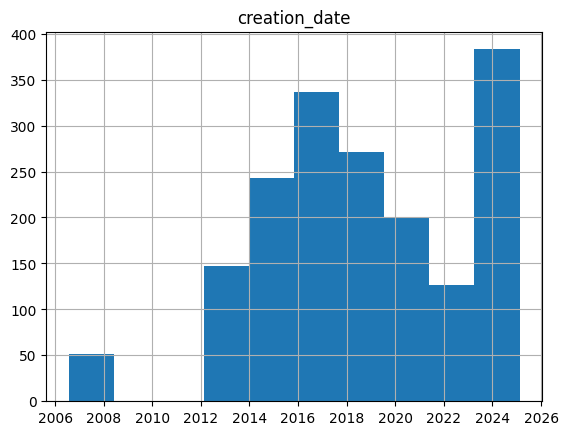

In [37]:
from datetime import datetime
filtered_df['creation_date'] = filtered_df['creation_date'].apply(lambda x: datetime.strptime(x, "%d-%b-%Y"))
filtered_df.hist('creation_date')

array([[<Axes: title={'center': 'trimed_seq_len'}>]], dtype=object)

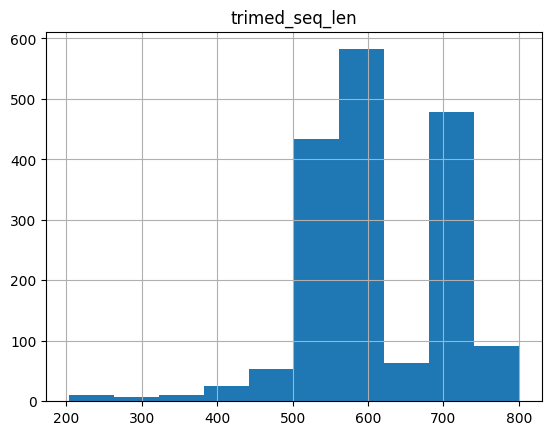

In [38]:
filtered_df.hist('trimed_seq_len')

In [39]:
def sanitize_org_name(org_name: str) -> str:
    org_name_arr = org_name.split(' ')
    to_remove = ['x', 'var.', 'var', 'aff.', 'aff', 'cf.', 'cf']
    for s in to_remove:
        try:
            org_name_arr.remove(s)
        except ValueError:
            pass
    return ' '.join(org_name_arr[:2])


In [40]:
filtered_df['tax_id_sanitized'] = filtered_df['tax_id']
filtered_df['organism_name_sanitized'] = filtered_df['organism_name'].apply(sanitize_org_name)
def fix_tax_id(row: pd.Series):
    if row['organism_name_sanitized'] == row['organism_name']:
        return row['tax_id']
    if row['organism_name_sanitized'] in filtered_df['organism_name'].unique():
        new_tax_id = filtered_df.loc[filtered_df['organism_name'] == row['organism_name_sanitized']]['tax_id'].iloc[0]
        return new_tax_id
    return row['tax_id']

filtered_df['tax_id_sanitized'] = filtered_df.apply(fix_tax_id, axis=1)
sane_species = filtered_df[filtered_df['organism_name'].str.count(' ') == 1]
dup_species = filtered_df[filtered_df['organism_name'].str.count(' ') > 1]
dup_species.to_csv('dup-species.csv')
filtered_df.value_counts('tax_id_sanitized')

tax_id_sanitized
65357      67
907947     52
143453     37
4792       30
4793       17
           ..
3073780     1
3073781     1
3073782     1
3073783     1
3073787     1
Name: count, Length: 728, dtype: int64

In [41]:
tax_db = pd.read_csv('data/tax-filtered.csv', sep='\t')
seq_and_tax = filtered_df.merge(tax_db, right_on='tax_id', left_on='tax_id_sanitized', how='left')
# remove sequences with unknown taxonomy info
seq_and_tax = seq_and_tax.dropna(subset='genus')
seq_and_tax

,accession,creation_date,title,authors,sequence,sequence_length,organism_name,tax_id_x,cox2_start,cox2_end,...,organism_name_sanitized,tax_id_y,species,domain,kingdom,phylum,class,order,family,genus
0,L04457.1,2016-07-25,Phytophthora megasperma cytochrome c oxidase s...,"Shumard-Hudspeth,D.S. and Hudspeth,M.E.",ATGACAATCACAAATTATATCAACAATCAATTCACTTTTTTAGATA...,3572,Phytophthora megasperma,4788,793,1594,...,Phytophthora megasperma,4788.0,Phytophthora megasperma,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
1,BK011976.1,2022-05-09,TPA_asm: Hyaloperonospora arabidopsidis isolat...,"Winkworth,R.C., Neal,G., Ogas,R.A., Nelson,B.C...",ATGGTAATCAAAAATTATATAATAGATAAGCAATCTACTTTTTTAG...,38797,Hyaloperonospora arabidopsidis,272952,24700,25480,...,Hyaloperonospora arabidopsidis,272952.0,Hyaloperonospora arabidopsidis,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Hyaloperonospora
2,AY894835.1,2016-07-26,Phytophthora infestans haplotype Ia mitochondr...,"Avila-Adame,C., Gomez-Alpizar,L., Zismann,V., ...",ATGACAATAACAAATTATATAAATAATCAATTTACTTTTTTAGATA...,37922,Phytophthora infestans,4787,7624,8401,...,Phytophthora infestans,4787.0,Phytophthora infestans,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
3,KJ408269.1,2015-04-02,"Phytophthora andina mitochondrion, partial genome","Lassiter,E.S., Russ,C., Nusbaum,C., Zeng,Q., S...",ATGACAATAACAAATTATATAAATAATCAATTTACTTTTTTAGATA...,37883,Phytophthora andina,283009,7617,8394,...,Phytophthora andina,283009.0,Phytophthora andina,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
4,MH286887.1,2019-03-19,Phytophthora infestans voucher IT199999 mitoch...,"Cho,K.-S., Choi,J.-G., Cho,J.-H., Im,J.-S., Pa...",TTATACATTAAAATCAAAATTAATTTTATTTTTTAACCAAGTTAAA...,39872,Phytophthora infestans,4787,38640,39417,...,Phytophthora infestans,4787.0,Phytophthora infestans,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1752,HM628758.1,2017-12-07,Plasmopara viticola strain U366 voucher HUH ex...,"Schroeder,S., Telle,S., Nick,P. and Thines,M.",TACTGGAGTTATGAATATTCCGATAATTTAGAGTTTTCAGATGAAC...,248,Plasmopara viticola,143451,<0,>248,...,Plasmopara viticola,143451.0,Plasmopara viticola,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Plasmopara
1753,KP979650.1,2015-03-30,Peronosclerospora sorghi isolate 3BSJBPS1 cyto...,"Rustiani,U.S., Sinaga,M.S., Wiyono,S. and Hida...",TCCAGCAACTCCAGTTATGGAAGGTATTATTAATTTTCATCATGAT...,241,Peronosclerospora sorghi,230839,<0,>241,...,Peronosclerospora sorghi,230839.0,Peronosclerospora sorghi,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Peronosclerospora
1754,EU595782.1,2016-07-26,Phytophthora sp. 4E4 cytochrome c oxidase subu...,"Hong,C., Gallegly,M.E., Richardson,P.A., Kong,...",CCATGGTATTGGAGTTACGAATATTCAGATAATTTAGAATTTTCAG...,210,Phytophthora irrigata,565287,<0,>210,...,Phytophthora irrigata,565287.0,Phytophthora irrigata,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Phytophthora
1755,MF372728.1,2017-07-23,Plasmopara destructor voucher GLM-F107554 cyto...,"Goerg,M., Ploch,S., Kruse,J., Kummer,V., Runge...",ACGGTATTGCCCAAGAATGTAAAACATCTGATGCAGTAATTAATAC...,203,Plasmopara destructor,2019374,<0,>203,...,Plasmopara destructor,2019374.0,Plasmopara destructor,Eukaryota,Sar,Stramenopiles,Oomycota,Peronosporales,Peronosporaceae,Plasmopara


In [42]:
seq_and_tax.to_csv('seq-and-tax.csv')

### Construct SINTAX compatible db

In [43]:
from Bio.Seq import Seq
with open('data/cox2-db-clust.fa', 'w') as out:
    for index, row in seq_and_tax.iterrows():
        print(f'>{row["accession"]};tax=d:{row["domain"]};k:{row["kingdom"]};p:{row["phylum"]};c:{row["class"]};o:{row["order"]};f:{row["family"]};g:{row["genus"]};s:{row["organism_name_sanitized"].replace(" ", "+")}', file=out)
        if int(row['cox2_strand']) == -1:
            seq = Seq(row['sequence'])
            print(seq.reverse_complement(), file=out)
        else:
            print(row['sequence'], file=out)